# Assignment 2

Hao YAN (hy2878)

Part 1 defines the CNN. Part 2 loads CIFAR-10, trains the model, evaluates it, and saves the checkpoint for the API.

Install these packages in the notebook kernel before running the cells:

```python
%pip install torch torchvision datasets matplotlib tqdm
```

The saved evaluation and plot outputs are from the local training run. The notebook can run from the repository root or the `notebooks` folder.


In [2]:
#Applied GenAI
#Hao YAN hy2878

import torch
import torch.nn as nn


In [3]:
class AssignmentCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # First convolution: 3 input channels - 16 output channels
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            stride=1,
            padding=1
        )

        # Second convolution: 16 input channels - 32 output channels
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            stride=1,
            padding=1
        )

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = nn.Flatten(start_dim=1)

        # After two pooling operations: 32 channels × 16 × 16
        self.fc1 = nn.Linear(32 * 16 * 16, 100)

        # Output scores for 10 classes
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)

        return x


model = AssignmentCNN()
print(model)

AssignmentCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=8192, out_features=100, bias=True)
  (fc2): Linear(in_features=100, out_features=10, bias=True)
)


In [ ]:
# Shape check
# 4 RGB images, each with height and width of 64
sample_images = torch.randn(4, 3, 64, 64)

with torch.no_grad():
    outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (4, 10)

print("Shape check passed.")

In [5]:
#Part 2
from pathlib import Path

import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


In [6]:
#download the CIFAR-10 dataset from huggingface
# %pip install datasets
from datasets import load_dataset

ds = load_dataset("uoft-cs/cifar10")
print(ds)

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})


In [ ]:
from pathlib import Path

import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "pyproject.toml").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
if not (PROJECT_DIR / "pyproject.toml").is_file():
    raise RuntimeError("Run this notebook from the repository or its notebooks folder.")

# Select the available device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# Resize images to match the assignment's input size
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])


class HFCIFAR10Dataset(Dataset):
    def __init__(self, data, transform):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample = self.data[index]

        image = sample["img"].convert("RGB")
        image = self.transform(image)
        label = int(sample["label"])

        return image, label


# Use the dataset already loaded into ds
train_dataset = HFCIFAR10Dataset(
    ds["train"], transform
)

test_dataset = HFCIFAR10Dataset(
    ds["test"], transform
)

class_names = ds["train"].features["label"].names
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Check the prepared data
batch_images, batch_labels = next(iter(train_loader))

print("Using device:", device)
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", class_names)
print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)

In [ ]:
# Set the random seed for reproducibility
torch.manual_seed(42)

# Initialize the model defined in Part 1
model = AssignmentCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 10
history = {"train_loss": [], "train_accuracy": []}

for epoch in range(EPOCHS):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        total_images += batch_size

    epoch_loss = total_loss / total_images
    epoch_accuracy = total_correct / total_images

    history["train_loss"].append(epoch_loss)
    history["train_accuracy"].append(epoch_accuracy)

    print(
        f"Loss: {epoch_loss:.4f} | "
        f"Training accuracy: {epoch_accuracy:.2%}"
    )

print("Training finished.")

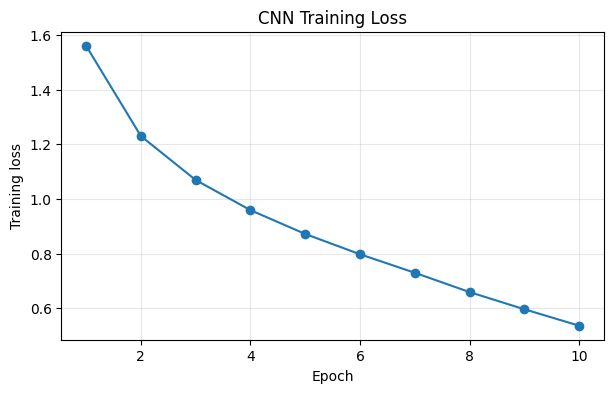

In [ ]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, EPOCHS + 1),
    history["train_loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("CNN Training Loss")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
model.eval()

test_loss_sum = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(
        test_loader,
        desc="Evaluating"
    ):
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        test_loss_sum += loss.item() * batch_size
        test_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        test_total += batch_size

test_loss = test_loss_sum / test_total
test_accuracy = test_correct / test_total

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Correct predictions: {test_correct}/{test_total}")

Evaluating: 100%|██████████| 157/157 [00:01<00:00, 93.86it/s] 

Test loss: 1.1032
Test accuracy: 65.82%
Correct predictions: 6582/10000


In [ ]:
MODEL_DIR = PROJECT_DIR / "app" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "cifar10_cnn.pth"

checkpoint = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in model.state_dict().items()
    },
    "class_names": class_names,
    "image_size": [64, 64],
    "preprocessing": "Resize((64, 64)) + ToTensor()",
    "epochs": EPOCHS,
    "test_accuracy": test_accuracy
}

torch.save(checkpoint, MODEL_PATH)

print("Model saved to:", MODEL_PATH)
print(f"File size: {MODEL_PATH.stat().st_size / 1024**2:.2f} MB")

In [ ]:
example = ds["test"][0]

image_path = PROJECT_DIR / "examples" / "test_image.png"
image_path.parent.mkdir(parents=True, exist_ok=True)
example["img"].save(image_path)

print("Image saved to:", image_path)
print("Actual class:", class_names[example["label"]])